In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [41]:
# I want to read data into memory.
df = pd.read_csv('data.csv')


In [42]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [43]:
#Checking the columns in the data set.
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [44]:
#To check the data types for the various columns
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [45]:
# another way of checking the various columns, their data types and whether they have missing values .info()
# also for checking number of columns, examples
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    object 
 4   Sex          418 non-null    object 
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    object 
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     object 
 11  Embarked     418 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 39.3+ KB


In [46]:
#checking the shape of our dataset
df.shape

(418, 12)

In [ ]:
dir(df)

In [47]:
#columns which have missing values
df.isnull().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

In [48]:
#bring the columns with missing values out.
[column for column in df.columns if df[column].isnull().sum() > 0]

['Age', 'Fare', 'Cabin']

In [49]:
#Ways of dealing with missing values
#dropping columns
#dropping rows
#replacing missing values with calculated mode, median, mean

In [50]:
#dropping the cabin column
df_new = df.drop('Cabin', axis = 1)
df_new

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,S
...,...,...,...,...,...,...,...,...,...,...,...
413,1305,0,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,S
416,1308,0,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,S


In [51]:
#we can now deal with age and fare row wise.
df_new = df_new.dropna()
df_new.shape

(331, 11)

In [52]:
#verify if missing values have been taken care of
df_new.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [53]:
#replace missing values with calculated median  .fillna()
df1 = df.copy()
df["Age"].fillna(df["Age"].median(), inplace = True)
df["Fare"].fillna(df["Fare"].median(), inplace = True)

In [54]:
# now checking columns with missing values again 
[column for column in df.columns if df[column].isnull().sum() > 0]

['Age', 'Fare', 'Cabin']

In [55]:
#Selecting some parts of the data (columns)
#create a column list of the columns we want to use as our new df
column_list = ["Sex", "Age", "Survived"]
new_df = df1[column_list]
new_df

,Sex,Age,Survived
0,male,34.5,0
1,female,47.0,1
2,male,62.0,0
3,male,27.0,0
4,female,22.0,1
...,...,...,...
413,male,NaN,0
414,female,39.0,1
415,male,38.5,0
416,male,NaN,0


In [57]:
## visualizing correlation between features with a heatmap
corr_matirix = df.corr()
sns.heatmap(corr_matirix, annot=True, cmap='coolwarm')
plt.show()

ValueError: could not convert string to float: 'Kelly, Mr. James'

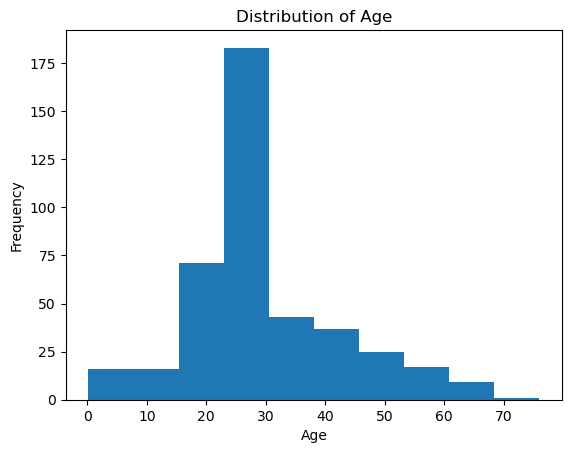

In [58]:
## ploting a histogram to show the frequency of Age .hist()
plt.hist(df['Age'])
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Distribution of Age')
plt.show()

In [ ]:
## showing the relationship between Age and Fare with a scatterplot .scatter()
plt.scatter(df['Age'], df['Fare'])
plt.xlabel('Age')
plt.ylabel('Fare')
plt.title('Age vs Fare')
plt.show()

In [ ]:
## barplot  to show survival status sns.countplot()
sns.countplot(data=df, x='Survived')
plt.xlabel('Survival Status')
plt.ylabel('Count')
plt.title('Survival Count')
plt.show()

In [ ]:
## row indexing with .iloc
df_row = df.iloc[100:200]
df_row.shape

In [ ]:
#columns indexing
df2 = df.iloc[:, 1:5]
df2